<a href="https://colab.research.google.com/github/vicradon/emotion-detection/blob/main/emotion_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

!yolo settings sync=False

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 39.1/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
!pip install -q roboflow

from roboflow import Roboflow
from google.colab import userdata
roboflow_api_key = userdata.get('roboflow_api_key')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("school-ytrhi").project("emotion-zjj8h")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to emotion-1 in yolov8:: 100%|██████████| 6792/6792 [00:01<00:00, 4492.94it/s]


In [ ]:
!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=50 imgsz=640 plots=True

New https://pypi.org/project/ultralytics/8.3.235 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/emotion-1/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, sa

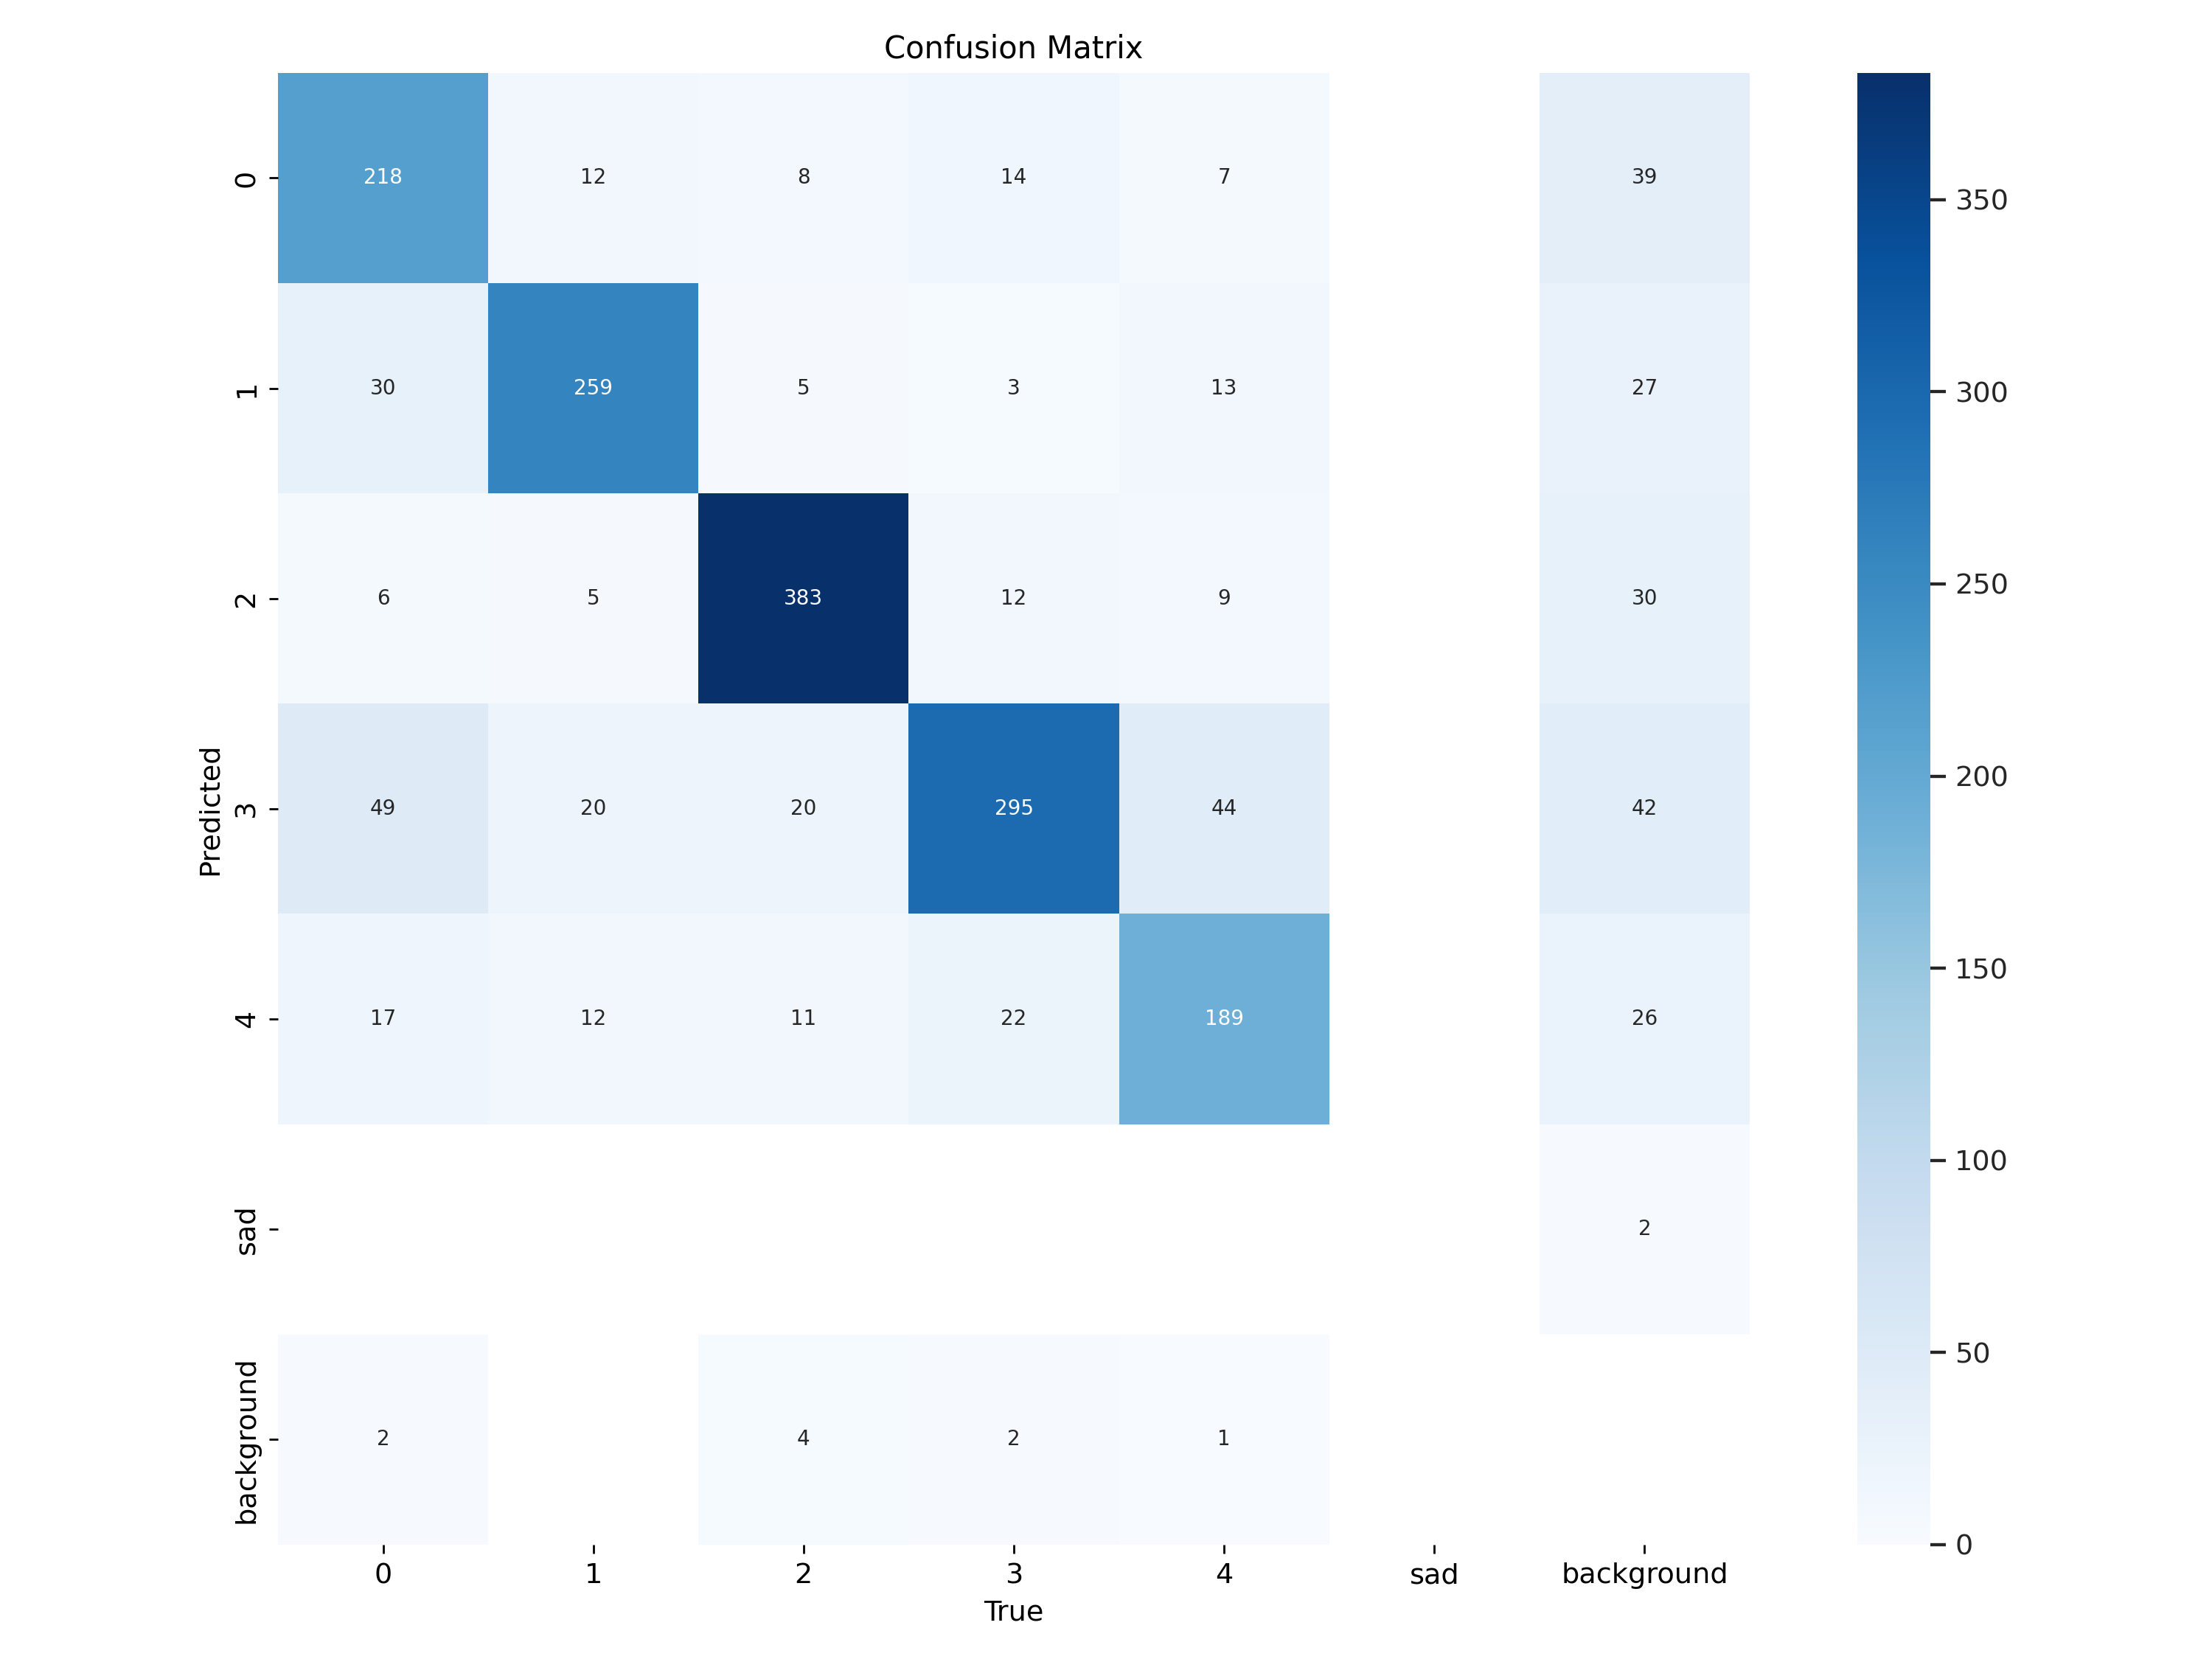

In [ ]:
Image(filename=f'/content/runs/detect/train3/confusion_matrix.png', width=600)

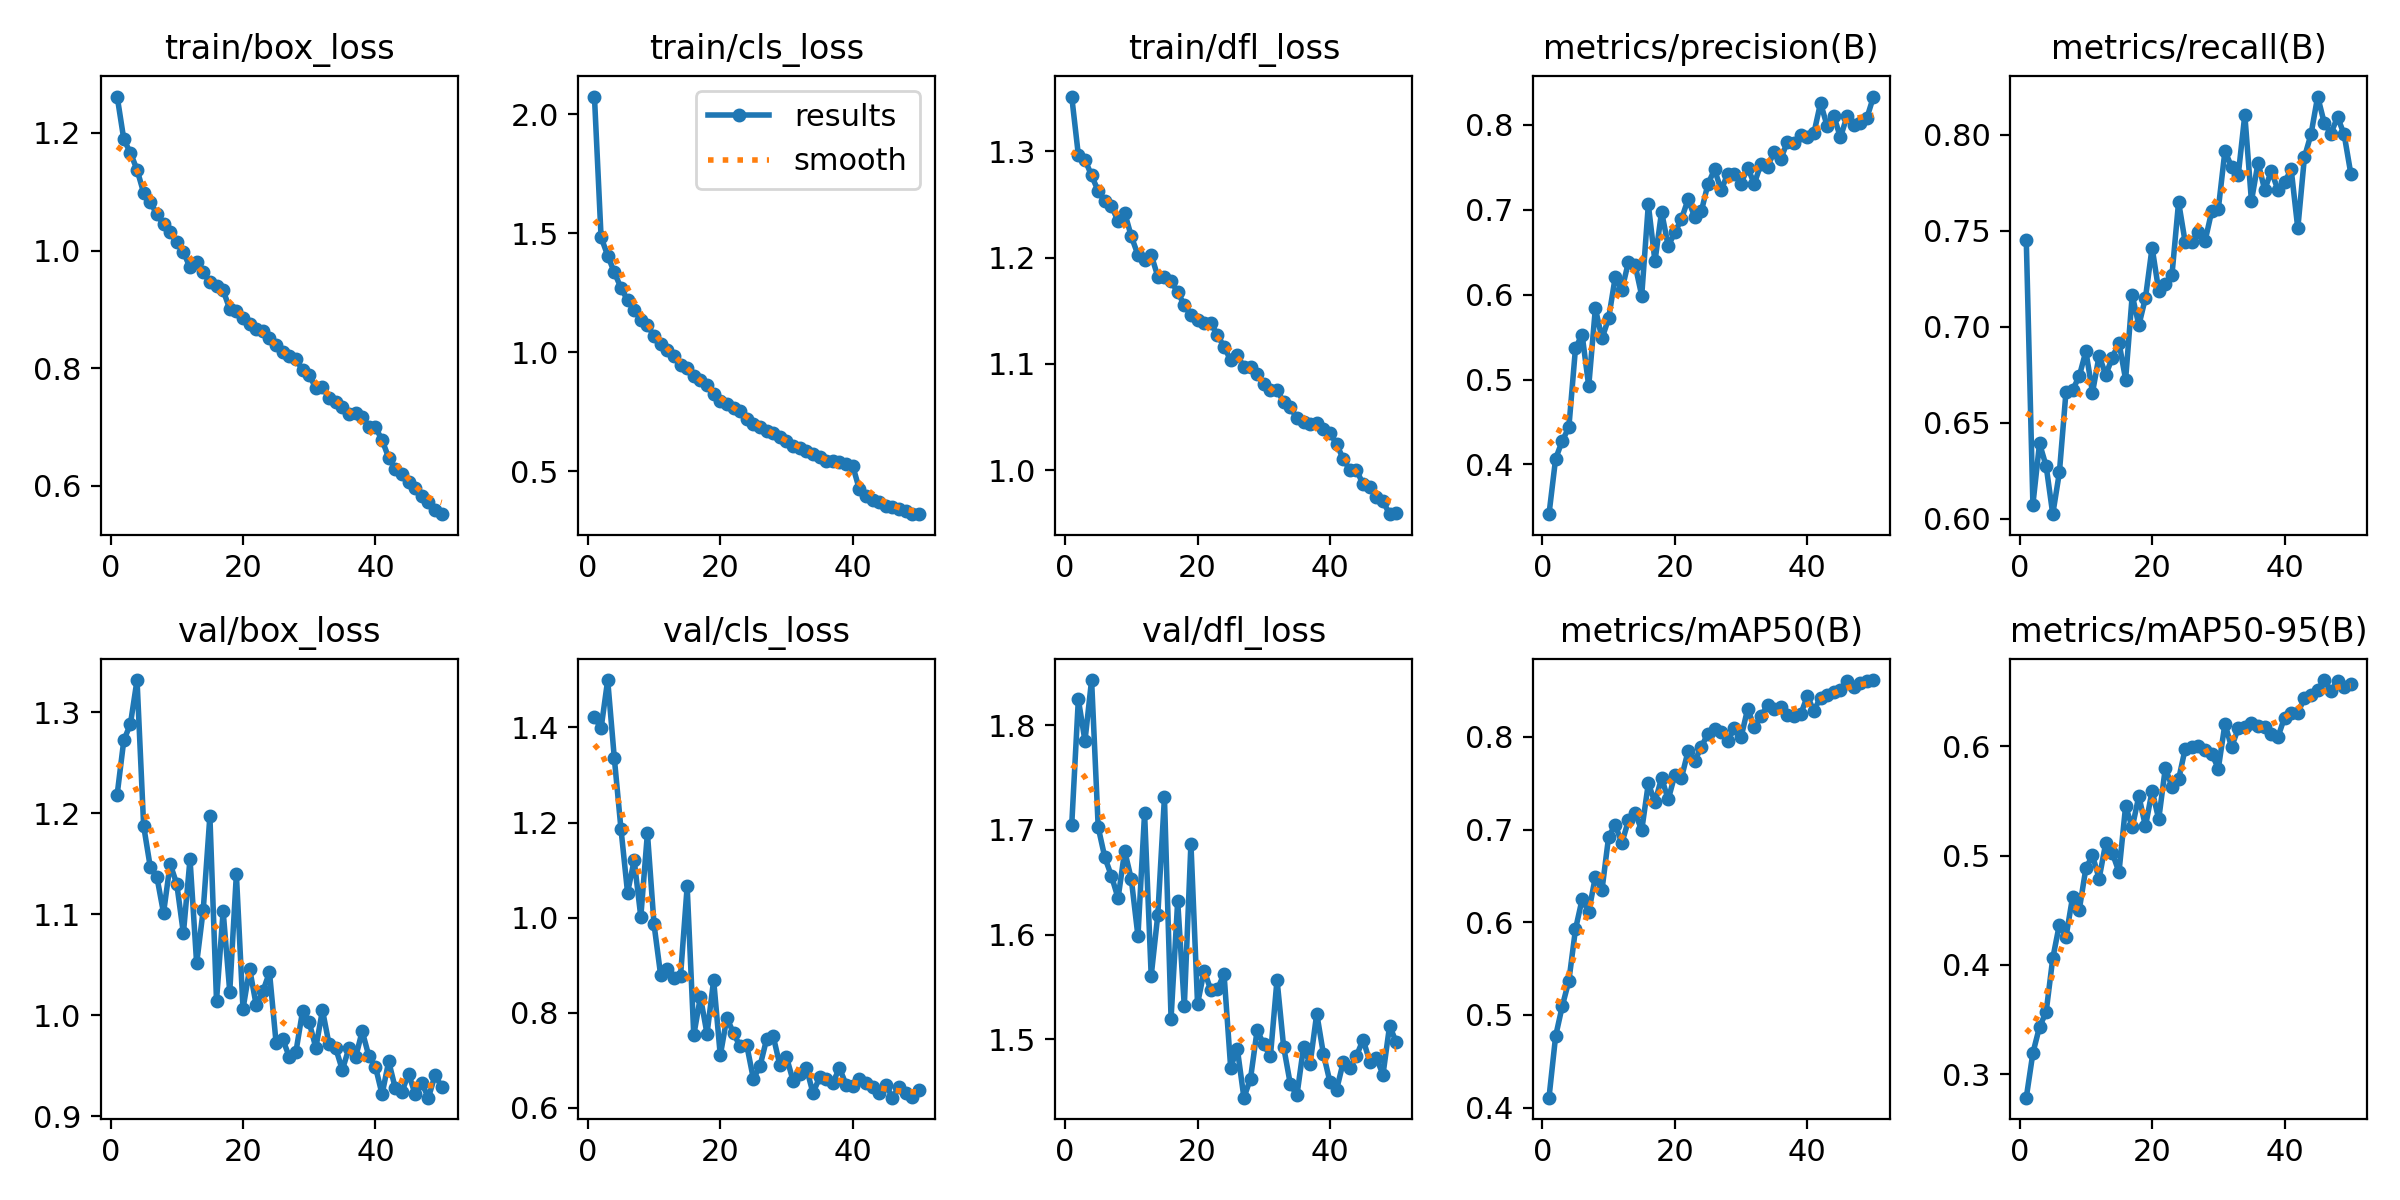

In [ ]:
Image(filename=f'/content/runs/detect/train3/results.png', width=1200)

In [ ]:
!yolo task=detect mode=val model=/content/runs/detect/train3/weights/best.pt data={dataset.location}/data.yaml

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 168 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Scanning /content/emotion-1/valid/labels.cache... 288 images, 0 backgrounds, 0 corrupt: 100% 288/288 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 18/18 [00:05<00:00,  3.54it/s]
                   all        288       1672       0.81      0.807       0.86       0.66
                     0        138        322      0.828      0.708      0.836      0.651
                     1        128        308      0.847      0.844      0.897      0.697
                     2        147        431      0.906      0.886       0.95      0.731
                     3         92        348      0.684      0.856       0.81      0.614
                     4        124        263      0.784      0.738       0.81      0.608
Speed: 1.4ms preprocess, 8.5ms inference, 0.0m

In [ ]:
!yolo task=detect mode=predict model=/content/runs/detect/train3/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 168 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs

image 1/144 /content/emotion-1/test/images/13_jpg.rf.5a85118215172e01a8d44b6bdac6eb7b.jpg: 640x640 4 0s, 2 1s, 7 2s, 2 3s, 1 4, 16.2ms
image 2/144 /content/emotion-1/test/images/15_jpg.rf.9c929da637f79975d5b357433666aee3.jpg: 640x640 1 1, 4 2s, 9 3s, 2 4s, 16.3ms
image 3/144 /content/emotion-1/test/images/16_jpg.rf.3ce3260b10e58d05c336631c149b55eb.jpg: 640x640 2 0s, 3 1s, 3 2s, 4 3s, 4 4s, 16.2ms
image 4/144 /content/emotion-1/test/images/17_jpg.rf.1cf74acd088e45cba7ecf7d2e9e3c41d.jpg: 640x640 5 1s, 2 2s, 8 3s, 2 4s, 16.2ms
image 5/144 /content/emotion-1/test/images/17_jpg.rf.6ce0cb0673116d5bf7516a913f43eeed.jpg: 640x640 1 0, 5 1s, 5 2s, 6 3s, 1 4, 16.2ms
image 6/144 /content/emotion-1/test/images/17_jpg.rf.fe5cb59f3087b8a93965d65caf8c076b.jpg: 640x640 4 0s, 1 1, 4 2s, 5 3s, 4 4s, 16.3ms
image 7/144 /content/emotion-

**NOTE:** Let's take a look at few results.

In [ ]:
import glob
from IPython.display import Image, display

# Define the base path where the folders are located
base_path = '/content/runs/detect/'

# List all directories that start with 'predict' in the base path
subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

# Find the latest folder by modification time
latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:3]

# Display each image
for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")

NameError: name 'os' is not defined